In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Count:", torch.cuda.device_count())
else:
    print("GPU is NOT connected!")

CUDA Available: True
GPU Name: Tesla T4
GPU Count: 1


In [9]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [10]:
import os

print("Drive contents:")
print(os.listdir('/content/drive'))

print("\nMyDrive contents:")
print(os.listdir('/content/drive/MyDrive'))

Drive contents:
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']

MyDrive contents:
['بی\u200cنام (1).gdoc', 'بی\u200cنام.gdoc', 'eda_data.csv', 'data_eda.ipynb']


In [11]:
df = pd.read_csv('/content/drive/MyDrive/eda_data.csv')

df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,...,age,python_yn,R_yn,spark,aws,excel,job_simp,seniority,desc_len,num_comp
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,...,54,1,0,0,0,0,data scientist,na,2536,0
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,...,43,1,0,0,0,0,data scientist,na,4783,0
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,...,17,1,0,1,0,0,data scientist,na,3461,0
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,...,62,1,0,0,0,0,data scientist,na,3883,3
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,...,29,1,0,0,0,0,data scientist,na,2728,3


In [12]:
# df = pd.read_csv('eda_data.csv')
# df.head()

In [13]:
# choose relevant columns


In [14]:
df.columns

Index(['Unnamed: 0', 'Job Title', 'Salary Estimate', 'Job Description',
       'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'hourly', 'employer_provided', 'min_salary', 'max_salary', 'avg_salary',
       'Company_text', 'job_state', 'same_state', 'age', 'python_yn', 'R_yn',
       'spark', 'aws', 'excel', 'job_simp', 'seniority', 'desc_len',
       'num_comp'],
      dtype='object')

In [15]:
df_model= df[['avg_salary','Rating' , 'Size','Type of ownership' , 'Industry', 'Sector','hourly' , 'num_comp','employer_provided','job_state' ,'same_state' , 'age' ,'python_yn' ,'spark', 'aws', 'excel','job_simp', 'seniority', 'desc_len' ]]

In [16]:
#get dummy data
df_dum = pd.get_dummies(df_model, dtype=int)

In [17]:
#train test split
from sklearn.model_selection import train_test_split
x = df_dum.drop('avg_salary',axis=1)
y = df_dum.avg_salary.values
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

In [18]:
#multiple linear regression
import statsmodels.api as sm

x_sm = x =sm.add_constant(x)
model = sm.OLS(y , x_sm)
model.fit().summary()


/tmp/ipykernel_3125/843429644.py:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model.fit().summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.695
Model:                            OLS   Adj. R-squared:                  0.631
Method:                 Least Squares   F-statistic:                     10.82
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           3.10e-96
Time:                        12:15:41   Log-Likelihood:                -3327.2
No. Observations:                 742   AIC:                             6914.
Df Residuals:                     612   BIC:                             7514.
Df Model:                         129                                         
Covariance Type:            nonrobust                                         
=====================================================================================================================
                                                        coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
const                                                47.7187      6.871      6.945      0.000      34.225      61.212
Rating                                                1.4943      1.859      0.804      0.422      -2.157       5.146
hourly                                              -36.8805      8.680     -4.249      0.000     -53.927     -19.834
num_comp                                              2.0262      0.851      2.382      0.018       0.355       3.697
employer_provided                                    39.9162     11.305      3.531      0.000      17.716      62.117
same_state                                            1.6139      2.550      0.633      0.527      -3.394       6.622
age                                                   0.0539      0.028      1.954      0.051      -0.000       0.108
python_yn                                             8.3622      2.464      3.394      0.001       3.524      13.200
spark                                                -0.4887      2.855     -0.171      0.864      -6.095       5.118
aws                                                   3.0136      2.664      1.131      0.258      -2.217       8.244
excel                                              1.948e-11    7.5e-12      2.598      0.010    4.76e-12    3.42e-11
desc_len                                             -0.0001      0.001     -0.177      0.859      -0.002       0.001
Size_-1                                              16.1481     12.746      1.267      0.206      -8.884      41.180
Size_1 to 50 employees                                6.1549      5.845      1.053      0.293      -5.324      17.634
Size_10000+ employees                                 3.0906      4.484      0.689      0.491      -5.716      11.897
Size_1001 to 5000 employees                           4.2380      3.867      1.096      0.274      -3.357      11.833
Size_201 to 500 employees                            -0.3504      3.784     -0.093      0.926      -7.782       7.082
Size_5001 to 10000 employees                         -2.5153      4.955     -0.508      0.612     -12.246       7.216
Size_501 to 1000 employees                            1.6187      4.035      0.401      0.688      -6.306       9.543
Size_51 to 200 employees                              5.5296      3.999      1.383      0.167      -2.324      13.383
Size_Unknown                                         13.8047     13.457      1.026      0.305     -12.622      40.232
Type of ownership_-1                                 16.1481     12.746      1.267      0.206      -8.884      41.180
Type of ownership_College / University                3.2312     17.055      0.189      0.850     -30.262      36.724
Type of ownersh

In [19]:
from sklearn import linear_model 
from sklearn.model_selection import cross_val_score

lm = linear_model.LinearRegression()
lm.fit(X_train , y_train)
np.mean(cross_val_score(lm , X_train , y_train , scoring='neg_mean_absolute_error'))

np.float64(-19.80400085850119)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.208e+04, tolerance: 5.800e+01
  model = cd_fast.enet_coordinate_descent(


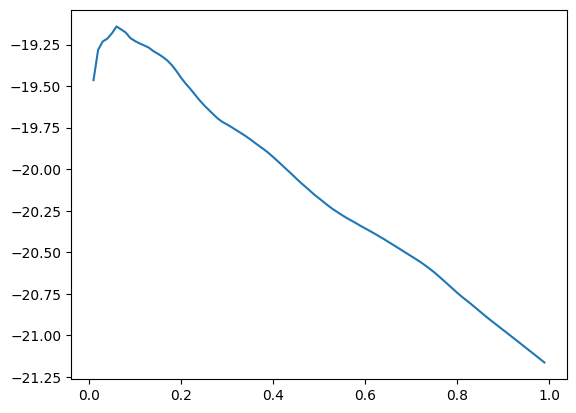

In [20]:
#lasso regression
lm_l = linear_model.Lasso(alpha=.06)
lm_l.fit(X_train,y_train)

np.mean(cross_val_score(lm_l , X_train , y_train , scoring='neg_mean_absolute_error'))

alpha=[]
error =[]

for i in range(1,100):
    alpha.append(i/100)
    lml = linear_model.Lasso(alpha=i/100)
    error.append(np.mean(cross_val_score(lml , X_train , y_train , scoring='neg_mean_absolute_error')))
    
plt.plot(alpha,error)


In [21]:
err = tuple(zip(alpha,error))
df_err = pd.DataFrame(err , columns=['alpha' , 'error'])
df_err[df_err.error == max(df_err.error)]

,alpha,error
5,0.06,-19.141467


In [22]:
#random forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
rf = RandomForestRegressor()
rf.fit(X_train , y_train)
pred_train = rf.predict(X_train)
pred_test  = rf.predict(X_test)

print('mean train' , mean_absolute_error(y_train , pred_train))
np.mean(cross_val_score(rf , X_train , y_train , scoring='neg_mean_absolute_error'))



mean train 5.305181086519115


np.float64(-15.814175858585855)

In [25]:
# tune models gridsearchCV
from sklearn.model_selection import GridSearchCV
parameters = {
    'n_estimators': range(10,100,10),
    'criterion': ['squared_error', 'absolute_error', 'friedman_mse', 'poisson'],   
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto','sqrt', 'log2']
}


gs = GridSearchCV(rf , parameters,scoring='neg_mean_absolute_error' ,cv=3)
gs.fit(X_train,y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
2916 fits failed out of a total of 8748.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2916 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    valida

GridSearchCV(cv=3, estimator=RandomForestRegressor(),
             param_grid={'criterion': ['squared_error', 'absolute_error',
                                       'friedman_mse', 'poisson'],
                         'max_depth': [None, 10, 20],
                         'max_features': ['auto', 'sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': range(10, 100, 10)},
             scoring='neg_mean_absolute_error')

In [37]:
#test ensembles
tpered_lm = lm.predict(X_test)
tpered_lml = lm_l.predict(X_test)
tpered_rf = gs.best_estimator_.predict(X_test)

In [38]:
mean_absolute_error(y_test , tpered_lm)

19.241847077489965

In [39]:
mean_absolute_error(y_test , tpered_lml)

19.196970041514483

In [40]:
mean_absolute_error(y_test , tpered_rf)

12.808775510204082